# AI and the Entry-Level Job Market: Employment Trends, AI Exposure, and Skills for Recent College Graduates📝

![Banner](./assets/banner.jpeg)

## Topic
*What problem are you (or your stakeholder) trying to address?*
📝 <!-- Answer Below -->

This issue I would like to adress is how artifical intelligence is affecting job opportunities for recent college grads. AI is becoming more common in every industry and is changing the way companies operate. Some tasks can now be completed faster using AI, which would reduce the need for some entry level roles while creating demand for new skills. The topic is important becuase recent college grads are already entering a competitive job marker. Understanding how AI is changing employment opportunities could help students make better decisions about their careers and identify skills they need to develop before graduattion. 

## Project Question
*What specific question are you seeking to answer with this project?*
*This is not the same as the questions you ask to limit the scope of the project.*
📝 <!-- Answer Below -->

How is increased AI use across occupations associated with employment outcomes for recent college graduates, and what skills are most common in occupations with higher AI use. 
How have unemployment rates among recent college grads changed as AI has become more common?
Which career fields have highest levels of AI use, and how are employment opportunities in that field?
Are entry-level job opportunities decreasing in occupations with higher AI use?
What tech and AI-related skills are employers looking for?


## What would an answer look like?
*What is your hypothesized answer to your question?*
📝 <!-- Answer Below -->

I would use line graphs, bar charts, and scatter plots to compare unployment trends, AI use, and job opportunities across diffrent career fields. I could also create a scatter plot comparing AI use with changes in the job opportunities for different occupations. Finally, a bar chart of commonly requested tech skills would help show what employers are looking for. The goal would be to identify patterns between AI adoption and employment trends. 

## Data Sources
*What 3 data sources have you identified for this project?*
*How are you going to relate these datasets?*
📝 <!-- Answer Below -->

https://www.newyorkfed.org/research/college-labor-market#--:explore:unemployment
This datasset provides information about unemployment, underemployment, and wages for recent college grads. I would use it examine how unemployment has changed over time. 

https://huggingface.co/datasets/Anthropic/EconomicIndex
This dataset provides information about how AI is being used for different occupation tasks. It also includes occupational AI-exposure data.  I would use it to idenity which career fields have higher levels of observed AI use. 

https://www.onetcenter.org/database.html
I will use O*Net to identify the skills and technologies required for different occupations. I will connect this information with the Anthropic dataset to compare the skills associated with jobs that have higher AI use. This will help me understand which technical skills may be useful for recent college grads. 

## Approach and Analysis
*What is your approach to answering your project question?*
*How will you use the identified data to answer your project question?*
📝 <!-- Start Discussing the project here; you can add as many code cells as you need -->

My apporach is to compare unemployment trends among recent college grads with AI adoption across different fields. I want to see if industries with higher AI use are experiecing changes in employment opportunities and what skills employers are looking for. I will use 3 datasets mentioned above. I plan to use python and sql to clean and organize data. I will connect the datasset using occupation codes and create visualization in tableau. My goal is to identify patterns that could help recent college grads understand how AI is chaning the job market and which skills they should focus on developing. However, a relationship between AI adoption and unemployment does not mean AI is directly causing unemployment. 

## Exploratory Data Analysis 


#### Analysis A - Are recent graduates having more difficulty finding work?


In [1]:
import pandas as pd

df_unemployed = pd.read_excel(
    "data/College-labor-data.xlsx",
    sheet_name="unemployed",
    header=10
)

df_unemployed.head()

,Date,Young workers,All workers,Recent graduates,College graduates
0,1990-01-01,7.603,5.132,3.381,2.270
1,1990-02-01,7.598,5.071,3.039,2.206
2,1990-03-01,7.608,5.049,3.136,2.165
3,1990-04-01,7.736,5.084,3.565,2.186
4,1990-05-01,7.661,5.121,3.861,2.198


In [3]:
df_unemployed.shape
df_unemployed.info()
df_unemployed.describe()
df_unemployed.isnull().sum()
df_unemployed.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438 entries, 0 to 437
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               438 non-null    datetime64[ns]
 1   Young workers      438 non-null    float64       
 2   All workers        438 non-null    float64       
 3   Recent graduates   438 non-null    float64       
 4   College graduates  438 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 17.2 KB


np.int64(0)

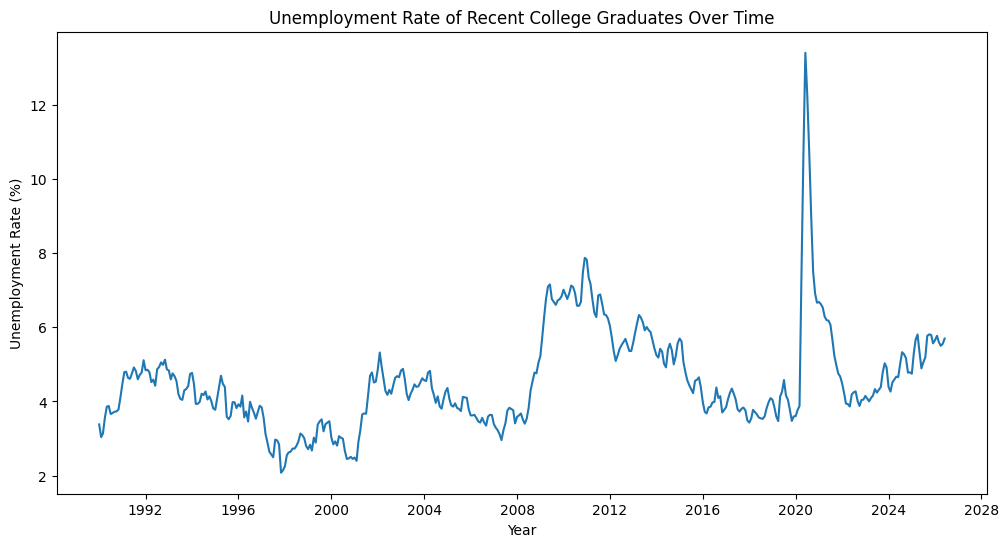

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    df_unemployed["Date"],
    df_unemployed["Recent graduates"]
)

plt.title("Unemployment Rate of Recent College Graduates Over Time")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")

plt.show()

##### Recent college graduate unemployment over time

This line graph shows how the unemployment rate for recent college graduates has changed over time. The rate has increased during several economic downturns, with the largest spike occurring around 2020. After decreasing again, unemployment among recent graduates has started to rise in the most recent years. This suggests that recent graduates may currently be facing a more difficult job market than they were a few years ago.

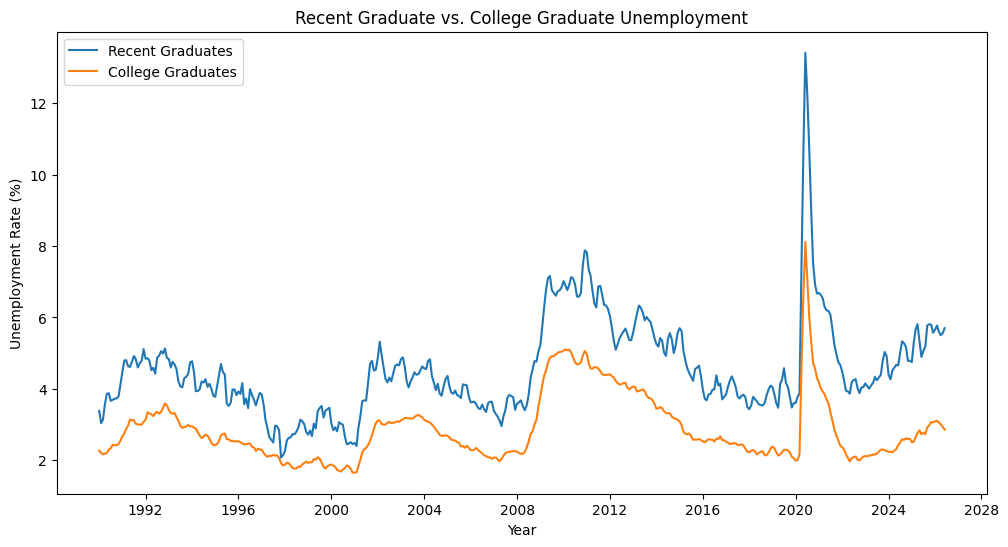

In [7]:
plt.figure(figsize=(12,6))

plt.plot(
    df_unemployed["Date"],
    df_unemployed["Recent graduates"],
    label="Recent Graduates"
)

plt.plot(
    df_unemployed["Date"],
    df_unemployed["College graduates"],
    label="College Graduates"
)

plt.title("Recent Graduate vs. College Graduate Unemployment")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.legend()

plt.show()

##### Recent Graduates vs. College Graduates

This graph compares the unemployment rate of recent college graduates with the unemployment rate of college graduates overall. Recent graduates consistently have a higher unemployment rate than the broader college graduate population. The difference becomes larger during periods of economic difficulty, especially around 2020. This suggests that recent graduates may be more vulnerable to changes in the job market.

##### Analysis B - Which occupations have the highest AI exposure?


In [9]:
df_ai = pd.read_csv("data/job_exposure.csv")

df_ai.head()

,occ_code,title,observed_exposure
0,11-1011,Chief Executives,0.0333
1,11-1021,General and Operations Managers,0.1378
2,11-1031,Legislators,0.0000
3,11-2011,Advertising and Promotions Managers,0.1731
4,11-2021,Marketing Managers,0.3195


In [11]:
df_ai.shape
df_ai.info()
df_ai.describe()
df_ai.isnull().sum()
df_ai.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   occ_code           756 non-null    object 
 1   title              756 non-null    object 
 2   observed_exposure  756 non-null    float64
dtypes: float64(1), object(2)
memory usage: 17.8+ KB


np.int64(0)

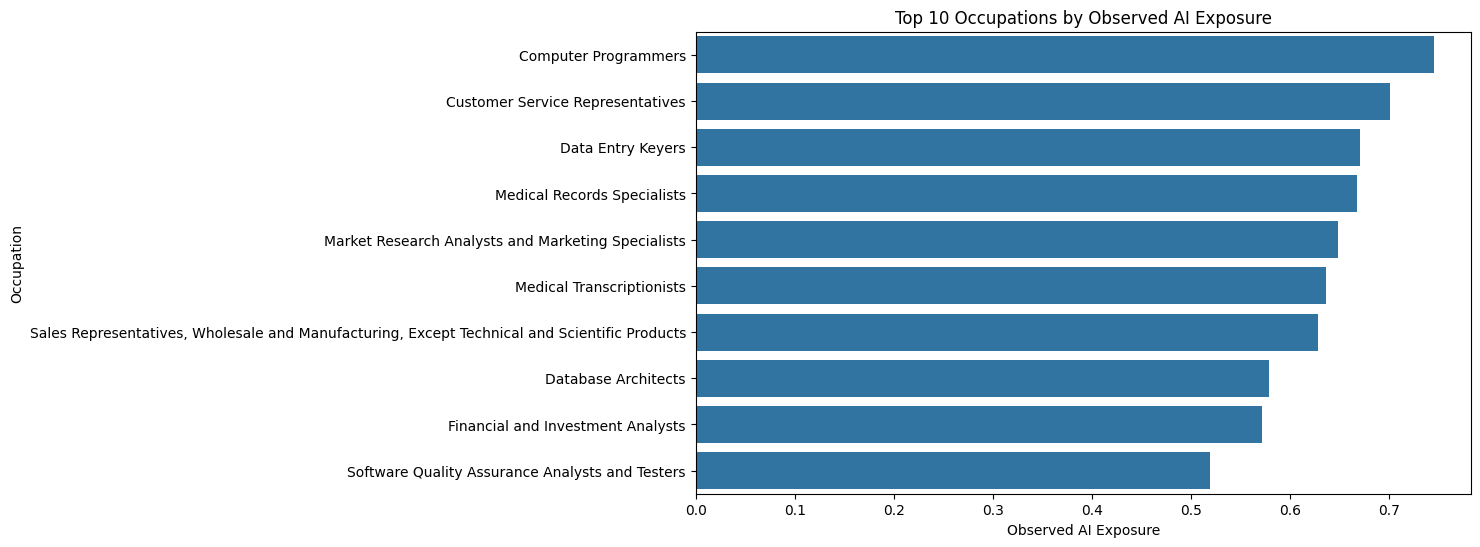

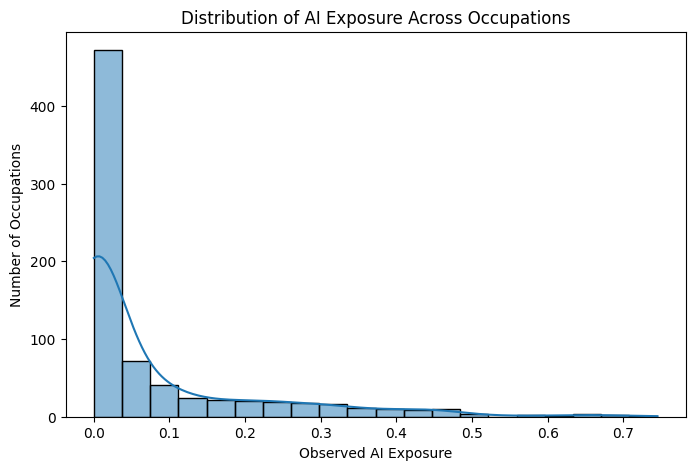

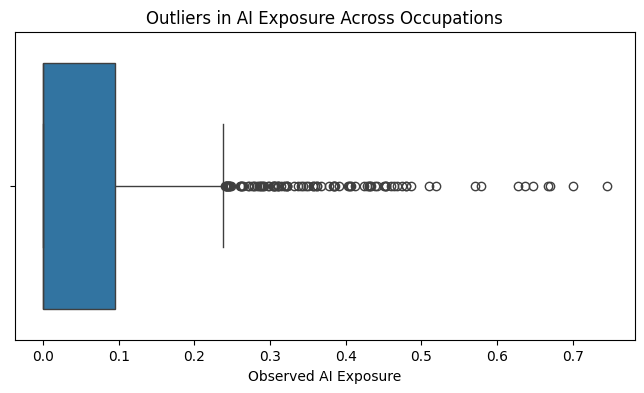

In [24]:
import seaborn as sns

top_ai = df_ai.sort_values(
    "observed_exposure",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_ai,
    x="observed_exposure",
    y="title"
)

plt.title("Top 10 Occupations by Observed AI Exposure")
plt.xlabel("Observed AI Exposure")
plt.ylabel("Occupation")

plt.show()

plt.figure(figsize=(8, 5))

sns.histplot(
    df_ai["observed_exposure"],
    bins=20,
    kde=True
)

plt.title("Distribution of AI Exposure Across Occupations")
plt.xlabel("Observed AI Exposure")
plt.ylabel("Number of Occupations")

plt.show()

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_ai["observed_exposure"]
)

plt.title("Outliers in AI Exposure Across Occupations")
plt.xlabel("Observed AI Exposure")

plt.show()

The distribution of observed AI exposure is strongly right-skewed. Most occupations have relatively low levels of AI exposure, while a smaller number of occupations have much higher exposure. The boxplot also identifies many higher-exposure occupations as outliers. I chose to keep these values because they represent real occupations rather than data errors, and these occupations are especially relevant to the purpose of this project.

The top 10 occupations by observed AI exposure include several technical, administrative, analytical, and information-based jobs. Computer Programmers have the highest observed exposure in this dataset, followed by occupations such as Customer Service Representatives and Data Entry Keyers. Other highly exposed occupations include Market Research Analysts, Database Architects, Financial and Investment Analysts, and Software Quality Assurance Analysts and Testers.

These results suggest that AI exposure is concentrated more heavily in occupations where work involves programming, data processing, analysis, communication, or repetitive information-based tasks.

##### Analysis C: What skills are associated with occupations that have higher AI exposure?


In [27]:
df_skills = pd.read_csv("data/software_skills.csv")

df_skills.head()

,O*NET-SOC Code,Title,Workplace Example,Element ID,Element Name,Hot Technology,In Demand
0,11-1011.00,Chief Executives,Adobe Acrobat,2.E.5.b,Document management software,Y,N
1,11-1011.00,Chief Executives,AdSense Tracker,2.E.6.f,Data base user interface and query software,N,N
2,11-1011.00,Chief Executives,Atlassian JIRA,2.E.5.a,Content workflow software,Y,N
3,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,2.E.6.c,Customer relationship management CRM software,N,N
4,11-1011.00,Chief Executives,ComputerEase construction accounting software,2.E.2.a,Accounting software,N,N


In [79]:
df_skills["occ_code"] = (
    df_skills["O*NET-SOC Code"]
    .str.split(".")
    .str[0]
)

df_skills[["O*NET-SOC Code", "occ_code"]].head()

,O*NET-SOC Code,occ_code
0,11-1011.00,11-1011
1,11-1011.00,11-1011
2,11-1011.00,11-1011
3,11-1011.00,11-1011
4,11-1011.00,11-1011


In [80]:
before = len(df_skills)

df_skills = df_skills.drop_duplicates(
    subset=["occ_code", "Workplace Example"]
)

print(f"Removed {before - len(df_skills)} duplicate occupation-software pairs")

Removed 0 duplicate occupation-software pairs


In [81]:
df_merged = pd.merge(
    df_ai,
    df_skills,
    on="occ_code",
    how="inner"
)

df_merged.head()

,occ_code,title,observed_exposure,O*NET-SOC Code,Title,Workplace Example,Element ID,Element Name,Hot Technology,In Demand
0,11-1011,Chief Executives,0.0333,11-1011.00,Chief Executives,Adobe Acrobat,2.E.5.b,Document management software,Y,N
1,11-1011,Chief Executives,0.0333,11-1011.00,Chief Executives,AdSense Tracker,2.E.6.f,Data base user interface and query software,N,N
2,11-1011,Chief Executives,0.0333,11-1011.00,Chief Executives,Atlassian JIRA,2.E.5.a,Content workflow software,Y,N
3,11-1011,Chief Executives,0.0333,11-1011.00,Chief Executives,Blackbaud The Raiser's Edge,2.E.6.c,Customer relationship management CRM software,N,N
4,11-1011,Chief Executives,0.0333,11-1011.00,Chief Executives,ComputerEase construction accounting software,2.E.2.a,Accounting software,N,N


In [82]:
ai_occupations = df_ai["occ_code"].nunique()
matched_occupations = df_merged["occ_code"].nunique()

print("Anthropic occupations:", ai_occupations)
print("Matched occupations:", matched_occupations)

match_rate = matched_occupations / ai_occupations * 100
print(f"Match rate: {match_rate:.2f}%")

Anthropic occupations: 756
Matched occupations: 756
Match rate: 100.00%


The Anthropic and O*NET datasets were combined using occupation codes. Because I used an inner merge, occupations without a matching O*NET software record were excluded. I checked the match rate to see how much of the original Anthropic occupation data was retained in the merged dataset.

In [83]:
df_merged.shape
df_merged[["occ_code", "title", "observed_exposure", "Workplace Example"]].head(10)

,occ_code,title,observed_exposure,Workplace Example
0,11-1011,Chief Executives,0.0333,Adobe Acrobat
1,11-1011,Chief Executives,0.0333,AdSense Tracker
2,11-1011,Chief Executives,0.0333,Atlassian JIRA
3,11-1011,Chief Executives,0.0333,Blackbaud The Raiser's Edge
4,11-1011,Chief Executives,0.0333,ComputerEase construction accounting software
5,11-1011,Chief Executives,0.0333,Database reporting software
6,11-1011,Chief Executives,0.0333,Databox
7,11-1011,Chief Executives,0.0333,Email software
8,11-1011,Chief Executives,0.0333,Exact Software Macola ES Labor Performance
9,11-1011,Chief Executives,0.0333,Extensible markup language XML


In [84]:
threshold = df_ai["observed_exposure"].quantile(0.75)

high_ai = df_merged[
    df_merged["observed_exposure"] >= threshold
]

In [93]:
top_skills = (
    high_ai.groupby("Workplace Example")["occ_code"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

top_skills

Workplace Example
Microsoft Excel              187
Microsoft Office software    187
Microsoft Word               183
Microsoft PowerPoint         182
Microsoft Outlook            165
Microsoft Access             132
Web browser software         131
SAP software                  80
Email software                77
Microsoft SharePoint          77
Name: occ_code, dtype: int64

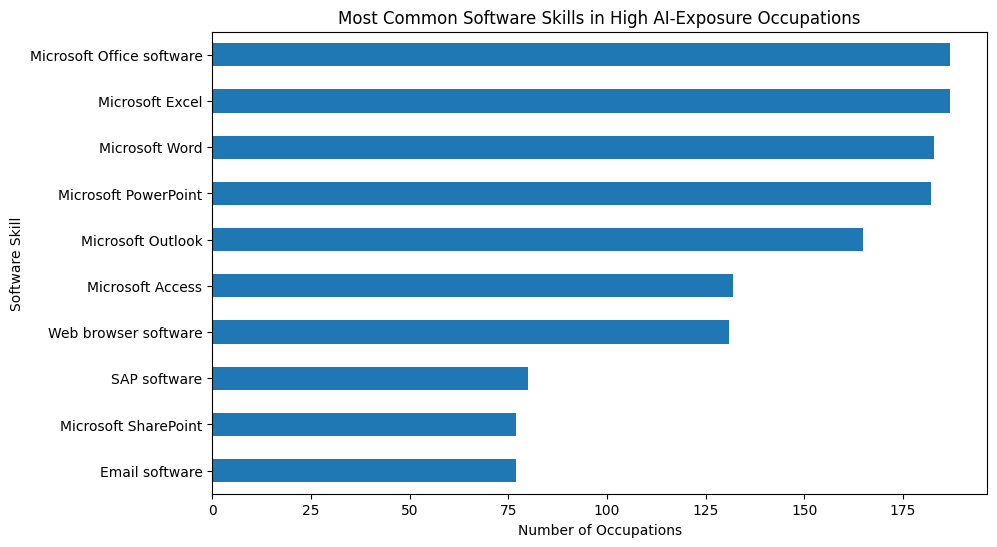

In [94]:
plt.figure(figsize=(10,6))

top_skills.sort_values().plot(kind="barh")

plt.title("Most Common Software Skills in High AI-Exposure Occupations")
plt.xlabel("Number of Occupations")
plt.ylabel("Software Skill")

plt.show()

This visualization shows the most common individual software skills found in occupations with high AI exposure. Microsoft Excel and Microsoft Office are the most common, followed by PowerPoint, Word, and Outlook. This suggests that many occupations with higher AI exposure still rely heavily on common productivity and data-related software. Excel may be especially important because it is commonly used for organizing, analyzing, and working with data.

In [101]:
top_categories = (
    high_ai.groupby("Element Name")["occ_code"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

top_categories

Element Name
Spreadsheet software                           187
Office suite software                          187
Word processing software                       184
Presentation software                          184
Electronic mail software                       179
Data base user interface and query software    175
Internet browser software                      144
Document management software                   118
Enterprise resource planning ERP software      105
Analytical or scientific software              104
Name: occ_code, dtype: int64

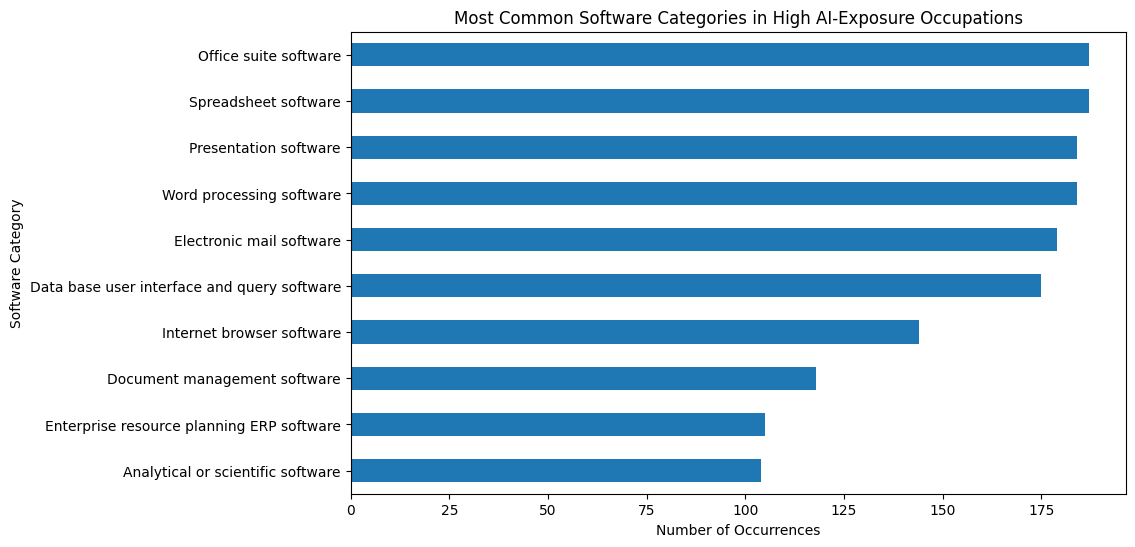

In [102]:
plt.figure(figsize=(10,6))

top_categories.sort_values().plot(kind="barh")

plt.title("Most Common Software Categories in High AI-Exposure Occupations")
plt.xlabel("Number of Occurrences")
plt.ylabel("Software Category")

plt.show()

This visualization groups software skills into broader categories. Database user interface and query software is the most common category, followed by analytical or scientific software and development environment software. Other common categories include web development, ERP, financial analysis, and database management software.

These results suggest that high AI-exposure occupations often involve working with databases, data analysis, software development, and other technical systems. For recent college graduates, developing skills in these areas may be useful when preparing for careers where AI is already being used frequently.

#### Correlation Analysis 

In [114]:
sw_count = df_merged.groupby("occ_code").agg(
    n_software=("Workplace Example", "nunique"),
    n_categories=("Element Name", "nunique"),
    observed_exposure=("observed_exposure", "first")
)

sw_count.corr()

,n_software,n_categories,observed_exposure
n_software,1.000000,0.901437,0.528713
n_categories,0.901437,1.000000,0.580900
observed_exposure,0.528713,0.580900,1.000000


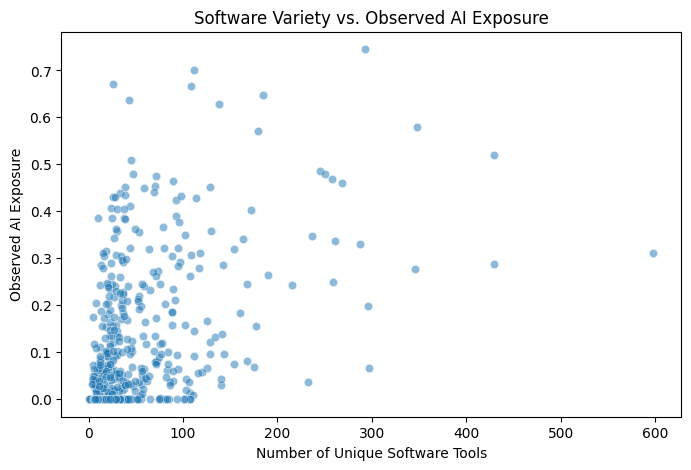

In [115]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sw_count,
    x="n_software",
    y="observed_exposure",
    alpha=0.5
)

plt.title("Software Variety vs. Observed AI Exposure")
plt.xlabel("Number of Unique Software Tools")
plt.ylabel("Observed AI Exposure")

plt.show()

##### Correlation Analysis

The correlation analysis shows a moderate positive relationship between software variety and observed AI exposure. This suggests that occupations that use a wider variety of software and software categories tend to have higher AI exposure.

However, the scatter plot still shows a large amount of variation, so software variety alone does not fully explain AI exposure. Other factors likely also influence how exposed an occupation is to AI.

The number of software tools and software categories are also strongly related to each other, which means they may contain similar information when used in the machine learning model.

These relationships show association only and do not mean that using more software causes higher AI exposure.

## Data Cleaning and Transformation
Before combining and analyzing the datasets, I checked for missing values, duplicate rows, outliers, and inconsistent data formats.

For the New York Fed unemployment dataset, I checked for missing values and duplicates. The dataset did not contain duplicate rows, and the main variables were already stored using appropriate data types. The Date column was stored as a datetime variable, while the unemployment variables were stored as numeric values.

For the Anthropic AI exposure dataset, I also checked for missing values and duplicate rows. The dataset contained 756 occupations, and the occupation codes were stored as text while observed AI exposure was stored as a numeric variable.

During the exploratory analysis, several occupations appeared as outliers because they had much higher AI exposure than most other occupations. I chose to keep these values because they represent real occupations rather than data-entry errors. Since one goal of this project is to identify occupations with unusually high AI exposure, removing these observations would remove important information from the analysis.

The main transformation involved combining the Anthropic and ONET datasets. The occupation codes were formatted differently in the two datasets. Anthropic used codes such as 11-1011, while ONET used codes such as 11-1011.00. I removed the decimal portion of the O*NET codes so that both datasets used the same format.

After standardizing the occupation codes, I used an inner merge to combine the Anthropic AI exposure data with the O*NET software skills data. The resulting dataset connects observed AI exposure with the software skills and software categories associated with each occupation.

After converting the O*NET occupation codes to the same format as the Anthropic codes, some detailed O*NET occupation variants collapsed into the same occupation code. This caused the same software tool to appear more than once for an occupation. I removed duplicate occupation-software pairs before performing the final analysis so that each software tool was only counted once per occupation.



In [116]:
df_skills.isnull().sum()
df_skills.duplicated().sum()

np.int64(0)

## Machine Learning Plan

For the machine learning portion of this project, I plan to use a regression model to predict the observed AI exposure of an occupation. The target variable will be observed_exposure from the Anthropic Economic Index.

Possible predictor variables will come from the O*NET dataset, including software categories, technology requirements, and other occupation characteristics. I plan to begin with a basic regression model and then compare it with a Random Forest Regressor because the relationship between occupational characteristics and AI exposure may not be completely linear.

One challenge is that the O*NET dataset contains many categorical software and technology variables. These variables may need to be encoded or grouped before they can be used in a machine learning model. Another challenge is that some occupations have many more listed software skills than others, which could create imbalance in the data.

To address these challenges, I plan to select the most relevant features, convert categorical variables into numeric form when necessary, and split the data into training and testing sets. I will evaluate the model using measures such as Mean Absolute Error, Mean Squared Error, and R-squared.

Before building the model, I will transform the O*NET data so that there is one row per occupation, with features such as the number of software tools and counts of different software categories. Because the dataset contains only about 756 occupations, I plan to use cross-validation rather than relying on a single train-test split.

I will also compare the models against a simple baseline that predicts the average AI exposure. Since the target variable is strongly right-skewed, I may test a square-root or log transformation. I will also watch for multicollinearity between predictors and may use Ridge or Lasso Regression to reduce the effect of highly related features.


## Prior Feedback and Updates
I was unable to receive feedback for Checkpoint #1 because I completed the work locally but did not push the code to GitHub. Because of this, my instructor and peers were not able to review my first checkpoint.

For Checkpoint #2, I reviewed my original project idea and made several updates based on what I learned while exploring the datasets. Originally, I planned to directly compare AI adoption with unemployment among recent college graduates. After examining the data more closely, I realized that the New York Fed dataset measures overall unemployment trends for recent graduates, while the Anthropic and O*NET datasets provide occupation-level information.

Because these datasets measure different levels of the labor market, I decided not to treat changes in unemployment as evidence that AI directly caused job losses. Instead, I use the New York Fed data to examine overall employment trends for recent graduates, while the Anthropic and O*NET datasets are used to identify occupations with higher AI exposure and the software skills associated with those occupations.

These changes helped make the project more focused and better aligned with what the available data can actually support.

## Resources and References
*What resources and references have you used for this project?*
📝 <!-- Answer Below -->

In [117]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

[NbConvertApp] Converting notebook source.ipynb to python
[NbConvertApp] Writing 17287 bytes to source.py
